# Занятие 4. Планирование траекторий и кинематическое управление — демонстрации

Учебник: Зенкевич С. Л., Ющенко А. С. «Основы управления манипуляционными роботами», глава 4 (§ 4.1, 4.2).
Модуль `trajlib.py` — профили, трапеция, многочлены, кубический сплайн с прогонкой, интерполяция в декартовом пространстве, слежение по закону $\dot{\mathbf q}=J^{+}(\dot{\mathbf s}^{\ast}+K\mathbf e)$, демпфирование и масштабирование скоростей. Библиотека `kinlib.py` даёт шестизвенник `make_ur()`.
Все демонстрации, кроме второй части шестой, выполнены для плоского двухзвенника с единичными звеньями. Числа сверяются с примерами 4.1–4.5 конспекта лекции 4.

| № | Демонстрация | Слайды | Лекция |
|---|---|---|---|
| 1 | Профили разгона — торможения, трапеция по ограничениям привода | 7–8 | 4.2, пример 4.1 |
| 2 | Многочлены третьей и пятой степени, цена гладкости | 12–13 | 4.3, пример 4.2 |
| 3 | Кубический сплайн: трёхдиагональная система и прогонка | 14–19 | 4.4, пример 4.3 |
| 4 | Синхронизация сочленений | 9 | 4.2 |
| 5 | Прямая в декартовом пространстве против прямой в пространстве сочленений | 27–28 | 4.5 |
| 6 | Окружность схвата через обратную задачу: двухзвенник и шестизвенник | 25–26, 29, 44 | 4.5, пример 4.4, ДЗ2 |
| 7 | Управление по вектору скорости с обратной связью по положению | 34–36, 38–39 | 4.8, пример 4.5 |
| 8 | Проход рядом с особой точкой и демпфирование | 40–41 | 4.9 |
| 9 | Ограничение скоростей приводов: срезание, масштабирование, замедление программы | 41 | 4.9 |
| 10 | Интерактивная модель | — | — |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))          # kinlib.py и trajlib.py лежат рядом с ноутбуком
import numpy as np
import matplotlib.pyplot as plt
from kinlib import make_ur, Frame
from trajlib import *
np.set_printoptions(precision=4, suppress=True)
plt.rcParams['figure.dpi'] = 100
%matplotlib inline
ru = lambda x, n=2: (('%.' + str(n) + 'f') % x).replace('.', ',')     # число с десятичной запятой

## 1. Профили разгона — торможения и трапеция по ограничениям привода (пример 4.1)

Специальная параметризация $\mathbf q(t)=\mathbf q^0+\lambda(t)(\mathbf q^1-\mathbf q^0)$. Единственное условие на профиль скорости $\dot\lambda(t)$ — единичная площадь, формула (4.8). Проверяем его численно для четырёх профилей учебника, затем считаем трапецию по ограничениям привода: $t_a=\dot q_{\max}/\ddot q_{\max}$, $T=\Delta q/\dot q_{\max}+t_a$.

постоянная скорость, 1/T   площадь под профилем = 1.0000, пик скорости = 1.000/T, наибольшее ускорение = 0.00/T²
треугольник, 2/T           площадь под профилем = 1.0000, пик скорости = 2.000/T, наибольшее ускорение = 4.00/T²
трапеция T/3, 3/(2T)       площадь под профилем = 1.0000, пик скорости = 1.500/T, наибольшее ускорение = 4.50/T²
(2/T) sin²(πt/T)           площадь под профилем = 1.0000, пик скорости = 2.000/T, наибольшее ускорение = 6.28/T²


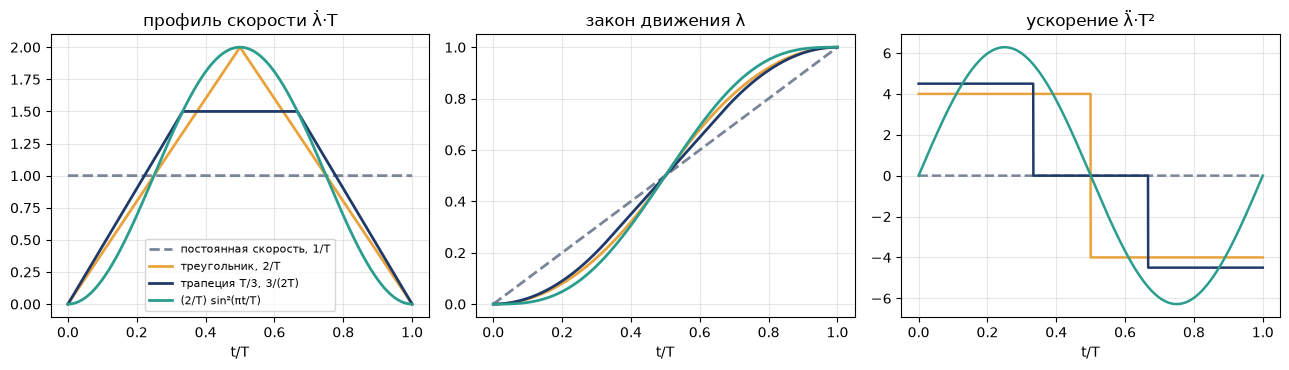

In [2]:
tau = np.linspace(0, 1, 2001)
profiles = (('постоянная скорость, 1/T', lam_rect, GREY, '--'), ('треугольник, 2/T', lam_tri, AMB, '-'),
            ('трапеция T/3, 3/(2T)', lam_trap, NAVY, '-'), ('(2/T) sin²(πt/T)', lam_sin2, TEAL, '-'))
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
for name, f, col, ls in profiles:
    l, dl, ddl = f(tau)
    axs[0].plot(tau, dl, color=col, ls=ls, lw=2, label=name); axs[1].plot(tau, l, color=col, ls=ls, lw=2)
    axs[2].plot(tau, ddl, color=col, ls=ls, lw=1.8)
    print('%-26s площадь под профилем = %.4f, пик скорости = %.3f/T, наибольшее ускорение = %.2f/T²' % (name, np.trapz(dl, tau), dl.max(), np.abs(ddl).max()))
for ax, ttl in zip(axs, ('профиль скорости λ̇·T', 'закон движения λ', 'ускорение λ̈·T²')):
    ax.set_title(ttl); ax.set_xlabel('t/T'); ax.grid(alpha=.3)
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

Δq = 1,5 рад: профиль trapezoid, t_a = 0,40 с, T = 1,90 с
Δq = 0,3 рад: профиль triangle, t_a = 0,35 с, T = 0,69 с, пиковая скорость 0,87 рад/с (предел 1 не достигнут)


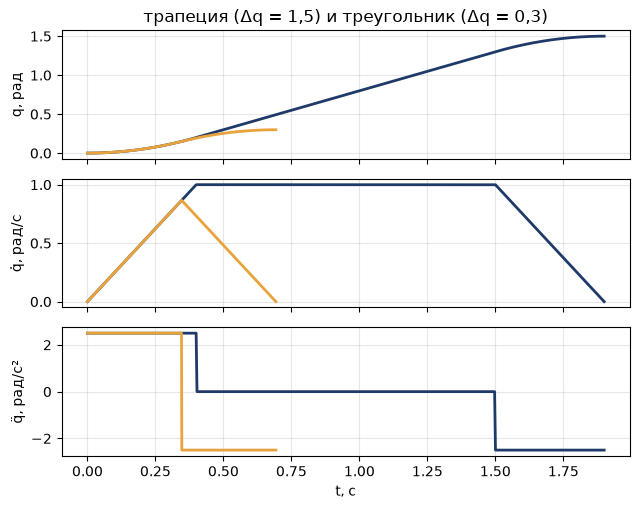

In [3]:
# Пример 4.1: трапеция по ограничениям привода
dq, vmax, amax = 1.5, 1.0, 2.5
tr = trapezoid(dq, vmax, amax)
print('Δq = 1,5 рад: профиль %s, t_a = %s с, T = %s с' % (tr['kind'], ru(tr['ta']), ru(tr['T'])))
tr2 = trapezoid(0.3, vmax, amax)
print('Δq = 0,3 рад: профиль %s, t_a = %s с, T = %s с, пиковая скорость %s рад/с (предел 1 не достигнут)' % (tr2['kind'], ru(tr2['ta']), ru(tr2['T']), ru(tr2['vpeak'])))
fig, axs = plt.subplots(3, 1, figsize=(6.5, 5.2), sharex=True)
for d_, t_, col in ((dq, tr, NAVY), (0.3, tr2, AMB)):
    t = np.linspace(0, t_['T'], 600); q, v, a = trap_eval(t, 0.0, d_, t_['ta'], t_['T'])
    for ax, y in zip(axs, (q, v, a)): ax.plot(t, y, color=col, lw=2)
for ax, yl in zip(axs, ('q, рад', 'q̇, рад/с', 'q̈, рад/с²')): ax.set_ylabel(yl); ax.grid(alpha=.3)
axs[0].set_title('трапеция (Δq = 1,5) и треугольник (Δq = 0,3)'); axs[2].set_xlabel('t, с'); plt.tight_layout(); plt.show()

## 2. Многочлены третьей и пятой степени (пример 4.2)

$\lambda_3=3\tau^2-2\tau^3$, $\lambda_5=10\tau^3-15\tau^4+6\tau^5$. Пики скорости $1{,}5$ и $15/8$, у кубического многочлена скачок ускорения $\pm6$ на концах, у многочлена пятой степени наибольшее ускорение $10/\sqrt3\approx5{,}77$. Время движения выбирается по ограничениям привода.

3-я степень: пик скорости 1.5000 Δ/T, наибольшее |ускорение| 6.0000 Δ/T², ускорение на концах +6.0 и -6.0
5-я степень: пик скорости 1.8750 Δ/T, наибольшее |ускорение| 5.7735 Δ/T², ускорение на концах +0.0 и +0.0


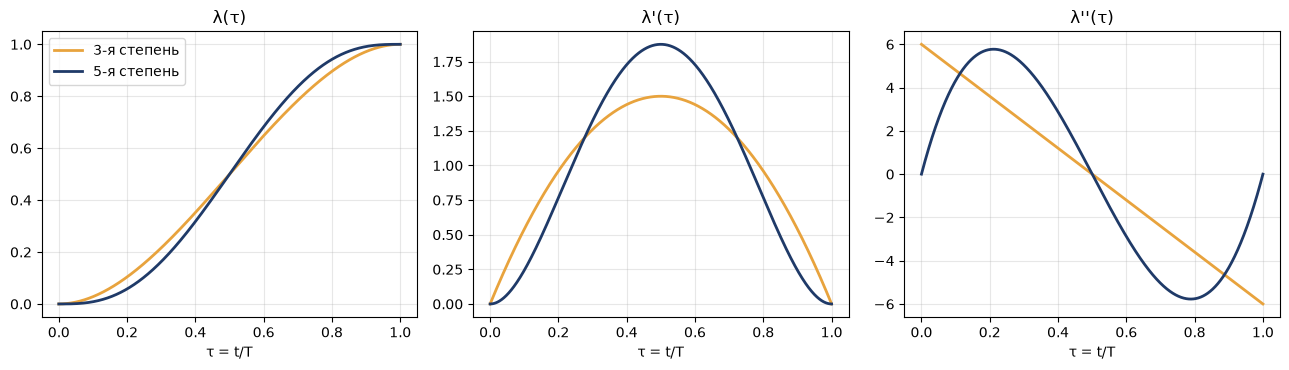

Пример 4.2: по скорости T >= 2,81 с, по ускорению T >= 1,86 с; принимаем T = 2,81 с
Трапеция выполняет то же перемещение за 1,90 с: гладкий закон медленнее в 1,48 раза


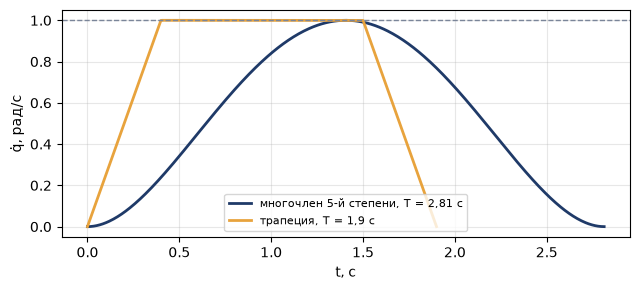

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
for name, f, col in (('3-я степень', lam_poly3, AMB), ('5-я степень', lam_poly5, NAVY)):
    l, dl, ddl = f(tau)
    for ax, y in zip(axs, (l, dl, ddl)): ax.plot(tau, y, color=col, lw=2, label=name)
    print('%s: пик скорости %.4f Δ/T, наибольшее |ускорение| %.4f Δ/T², ускорение на концах %+.1f и %+.1f' % (name, dl.max(), np.abs(ddl).max(), ddl[0], ddl[-1]))
for ax, ttl in zip(axs, ('λ(τ)', "λ'(τ)", "λ''(τ)")): ax.set_title(ttl); ax.set_xlabel('τ = t/T'); ax.grid(alpha=.3)
axs[0].legend(); plt.tight_layout(); plt.show()
T5, Tv, Ta = poly5_time(1.5, 1.0, 2.5)
print('Пример 4.2: по скорости T >= %s с, по ускорению T >= %s с; принимаем T = %s с' % (ru(Tv), ru(Ta), ru(T5)))
print('Трапеция выполняет то же перемещение за %s с: гладкий закон медленнее в %s раза' % (ru(tr['T']), ru(T5 / tr['T'])))
t = np.linspace(0, T5, 500)
plt.figure(figsize=(6.5, 3)); plt.plot(t, 1.5 * lam_poly5(t / T5)[1] / T5, color=NAVY, lw=2, label='многочлен 5-й степени, T = 2,81 с')
tt = np.linspace(0, tr['T'], 500); plt.plot(tt, trap_eval(tt, 0, 1.5, tr['ta'], tr['T'])[1], color=AMB, lw=2, label='трапеция, T = 1,9 с')
plt.axhline(1.0, color=GREY, ls='--', lw=1); plt.xlabel('t, с'); plt.ylabel('q̇, рад/с'); plt.legend(fontsize=8); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 3. Кубический сплайн: трёхдиагональная система и метод прогонки (пример 4.3)

Неизвестные — вторые производные в узлах: $\alpha_kq''_{k+1}+2q''_k+(1-\alpha_k)q''_{k-1}=M_k$, формула (4.21). Прогонка в форме учебника: $x_k=c_kx_{k+1}+d_k$. Узлы примера 4.3: $t_k=0,1,2,3$ с, $q_k=0;\,1;\,1{,}5;\,3$ рад, ускорения на концах нулевые. Ожидаем $q''=(0;\,-1{,}2;\,1{,}8;\,0)$.

k = 1: alpha = 0.5000, M = -1.5000, znamenatel = 2.0000, c = -0.2500, d = -0.7500
k = 2: alpha = 0.5000, M = 3.0000, znamenatel = 1.8750, c = -0.2667, d = 1.8000
естественный сплайн: q'' = [ 0.  -1.2  1.8  0. ]    начальная скорость q'_0 = 1.20 рад/с (не покой!)
нулевые скорости на концах: q'' = [ 4.4 -2.8  3.8 -6.4]   скорости в узлах: [-0.   0.8  1.3  0. ]   наибольшая скорость 2.01 рад/с


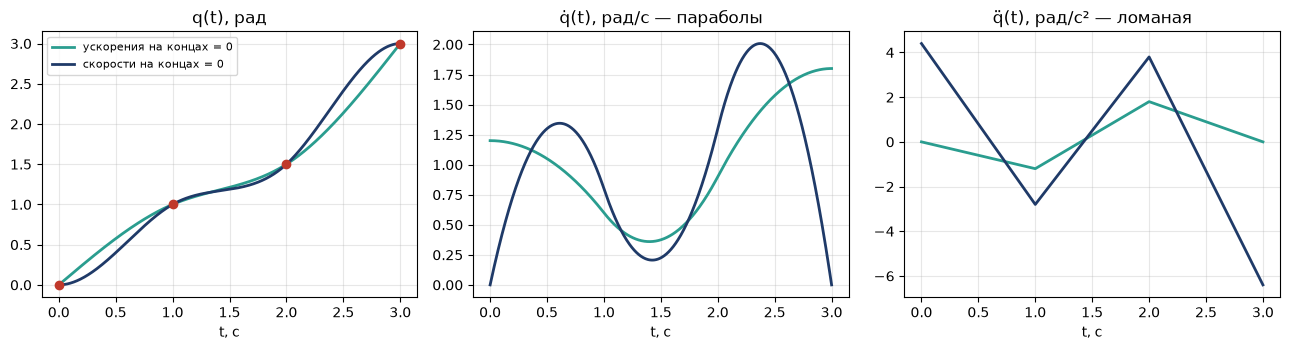

In [5]:
tk = np.array([0., 1., 2., 3.]); qk = np.array([0., 1., 1.5, 3.])
m_nat, c, d = sweep_book(tk, qk, 0.0, 0.0, verbose=True)
print("естественный сплайн: q'' =", m_nat, "   начальная скорость q'_0 = %.2f рад/с (не покой!)" % spline_eval(tk, qk, m_nat, tk)[1][0])
m_cl = spline_m(tk, qk, 'clamped', 0.0, 0.0)
vmax_s, amax_s = spline_extrema(tk, qk, m_cl)
print("нулевые скорости на концах: q'' =", m_cl, "  скорости в узлах:", spline_eval(tk, qk, m_cl, tk)[1].round(3), "  наибольшая скорость %.2f рад/с" % vmax_s)
x = np.linspace(0, 3, 601)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for m, col, name in ((m_nat, TEAL, 'ускорения на концах = 0'), (m_cl, NAVY, 'скорости на концах = 0')):
    for ax, y in zip(axs, spline_eval(tk, qk, m, x)): ax.plot(x, y, color=col, lw=2, label=name)
axs[0].plot(tk, qk, 'o', color=RED); axs[0].legend(fontsize=8)
for ax, ttl in zip(axs, ('q(t), рад', 'q̇(t), рад/с — параболы', 'q̈(t), рад/с² — ломаная')): ax.set_title(ttl); ax.set_xlabel('t, с'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

наибольшее отклонение многочлена 12-й степени от сплайна: 3.26 рад (размах самих узлов 1.60 рад)
сплайн: max|q̇| = 1.225 рад/с, max|q̈| = 4.188 рад/с²
ограничения 1.0 рад/с и 2.5 рад/с² -> растягиваем время в c = 1.294 раза: max|q̇| = 0.947 (в c раз меньше), max|q̈| = 2.500 (в c² раз меньше)


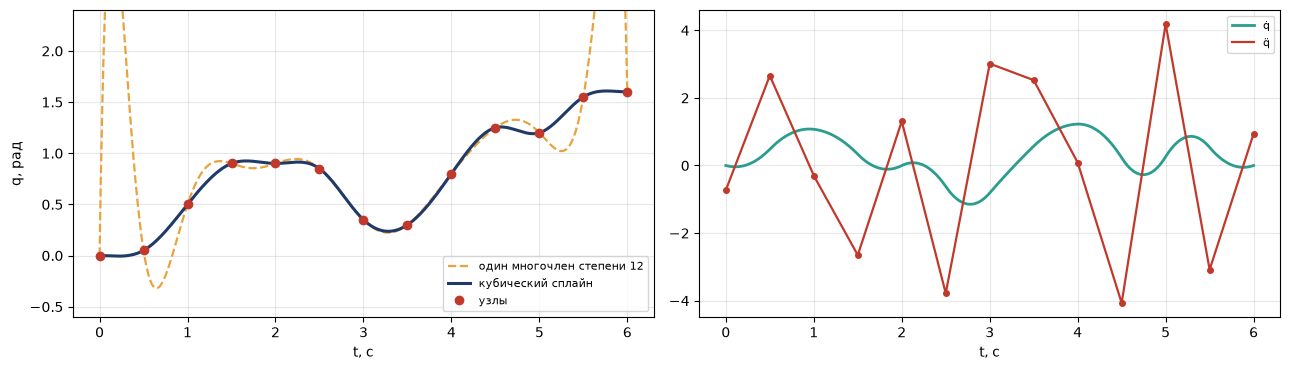

In [6]:
# Тринадцать узлов: сплайн против единого многочлена 12-й степени; проверка ограничений и растяжение времени
tk13 = np.linspace(0, 6, 13)
qk13 = np.array([0.0, 0.05, 0.5, 0.9, 0.9, 0.85, 0.35, 0.3, 0.8, 1.25, 1.2, 1.55, 1.6])
m13 = spline_m(tk13, qk13, 'clamped')
x = np.linspace(0, 6, 1201); s, ds, dds = spline_eval(tk13, qk13, m13, x)
pc = np.polyfit(tk13 - 3.0, qk13, 12); poly = np.polyval(pc, x - 3.0)
print('наибольшее отклонение многочлена 12-й степени от сплайна: %.2f рад (размах самих узлов %.2f рад)' % (np.abs(poly - s).max(), np.ptp(qk13)))
vm, am = spline_extrema(tk13, qk13, m13)
print('сплайн: max|q̇| = %.3f рад/с, max|q̈| = %.3f рад/с²' % (vm, am))
VMAX, AMAX = 1.0, 2.5
cst = max(vm / VMAX, np.sqrt(am / AMAX), 1.0)
m13s = spline_m(tk13 * cst, qk13, 'clamped'); vm2, am2 = spline_extrema(tk13 * cst, qk13, m13s)
print('ограничения %.1f рад/с и %.1f рад/с² -> растягиваем время в c = %.3f раза: max|q̇| = %.3f (в c раз меньше), max|q̈| = %.3f (в c² раз меньше)' % (VMAX, AMAX, cst, vm2, am2))
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
axs[0].plot(x, poly, color=AMB, ls='--', lw=1.6, label='один многочлен степени 12'); axs[0].plot(x, s, color=NAVY, lw=2.2, label='кубический сплайн')
axs[0].plot(tk13, qk13, 'o', color=RED, label='узлы'); axs[0].set_ylim(-0.6, 2.4); axs[0].legend(fontsize=8); axs[0].set_xlabel('t, с'); axs[0].set_ylabel('q, рад'); axs[0].grid(alpha=.3)
axs[1].plot(x, ds, color=TEAL, lw=2, label='q̇'); axs[1].plot(x, dds, color=RED, lw=1.6, label='q̈'); axs[1].plot(tk13, m13, 'o', color=RED, ms=4)
axs[1].legend(fontsize=8); axs[1].set_xlabel('t, с'); axs[1].grid(alpha=.3); plt.tight_layout(); plt.show()

## 4. Синхронизация сочленений

Общее время разгона $t_a=\max_i t_{a,i}$, общее время $T=\max_i(\Delta q_i/\dot q_i^{\max})+t_a$, затем $\dot q_i=\Delta q_i/(T-t_a)$, $\ddot q_i=\dot q_i/t_a$. Без синхронизации изображающая точка в плоскости $(q_1,q_2)$ идёт по ломаной, с синхронизацией — по прямой.

по отдельности: T1 = 1,90 с, T2 = 1,00 с
после синхронизации: t_a = 0,40 с, T = 1,90 с; скорости полки [1.  0.4] рад/с, ускорения [2.5 1. ] рад/с²


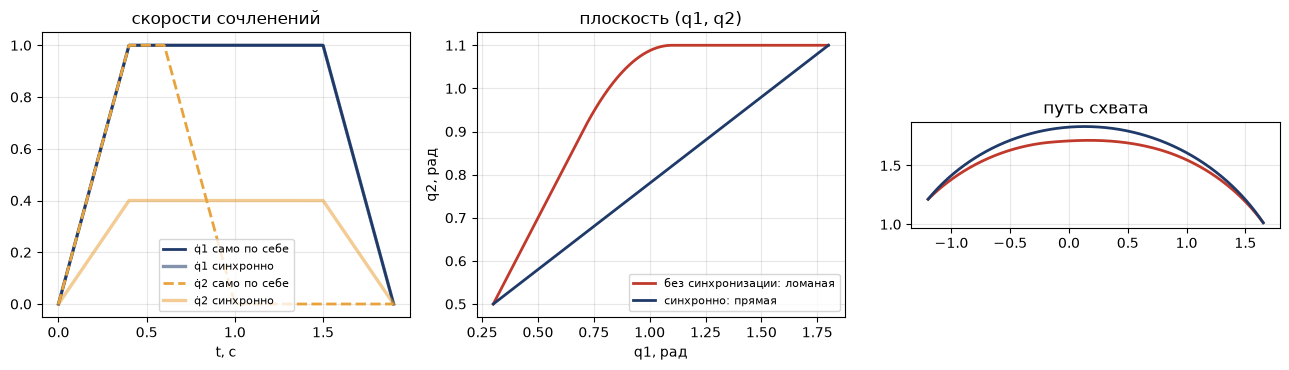

In [7]:
DQ = np.array([1.5, 0.6]); VM = np.array([1.0, 1.0]); AM = np.array([2.5, 2.5]); q_start = np.array([0.3, 0.5])
ind = [trapezoid(d_, v_, a_) for d_, v_, a_ in zip(DQ, VM, AM)]
ta, T, v, a = sync_trapezoid(DQ, VM, AM)
print('по отдельности: T1 = %s с, T2 = %s с' % (ru(ind[0]['T']), ru(ind[1]['T'])))
print('после синхронизации: t_a = %s с, T = %s с; скорости полки %s рад/с, ускорения %s рад/с²' % (ru(ta), ru(T), v, a))
t = np.linspace(0, T, 500)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
Qi = [trap_eval(t, q_start[i], q_start[i] + DQ[i], ind[i]['ta'], ind[i]['T']) for i in range(2)]
Qs = [trap_eval(t, q_start[i], q_start[i] + DQ[i], ta, T) for i in range(2)]
for i, col in enumerate((NAVY, AMB)):
    axs[0].plot(t, Qi[i][1], color=col, lw=2, ls='--' if i else '-', label='q̇%d само по себе' % (i + 1)); axs[0].plot(t, Qs[i][1], color=col, lw=2.4, alpha=.55, label='q̇%d синхронно' % (i + 1))
axs[0].legend(fontsize=8); axs[0].set_xlabel('t, с'); axs[0].set_title('скорости сочленений'); axs[0].grid(alpha=.3)
axs[1].plot(Qi[0][0], Qi[1][0], color=RED, lw=2, label='без синхронизации: ломаная'); axs[1].plot(Qs[0][0], Qs[1][0], color=NAVY, lw=2, label='синхронно: прямая')
axs[1].set_xlabel('q1, рад'); axs[1].set_ylabel('q2, рад'); axs[1].legend(fontsize=8); axs[1].set_title('плоскость (q1, q2)'); axs[1].grid(alpha=.3)
for Qx, col in ((Qi, RED), (Qs, NAVY)):
    P = np.array([fk2((a_, b_)) for a_, b_ in zip(Qx[0][0], Qx[1][0])]); axs[2].plot(P[:, 0], P[:, 1], color=col, lw=2)
axs[2].set_aspect('equal'); axs[2].set_title('путь схвата'); axs[2].grid(alpha=.3); plt.tight_layout(); plt.show()

## 5. Прямая в декартовом пространстве против прямой в пространстве сочленений

Двухзвенник идёт из $A=(1{,}6;\,-0{,}5)$ в $B=(0{,}3;\,1{,}5)$. Линейная интерполяция углов уводит схват от отрезка $AB$. Если же взять узлы на отрезке, а между узлами менять углы линейно, ошибка убывает как квадрат шага.

уход схвата от отрезка AB при прямой в пространстве сочленений: 0,54 м
    1 отрезков разбиения: наибольшее отклонение  535.814 мм
    8 отрезков разбиения: наибольшее отклонение   11.647 мм
   32 отрезков разбиения: наибольшее отклонение    0.767 мм
  128 отрезков разбиения: наибольшее отклонение    0.049 мм
отношение ошибок при удвоении числа отрезков: [3.05 3.86 3.91 3.88 3.91 3.94 3.97]


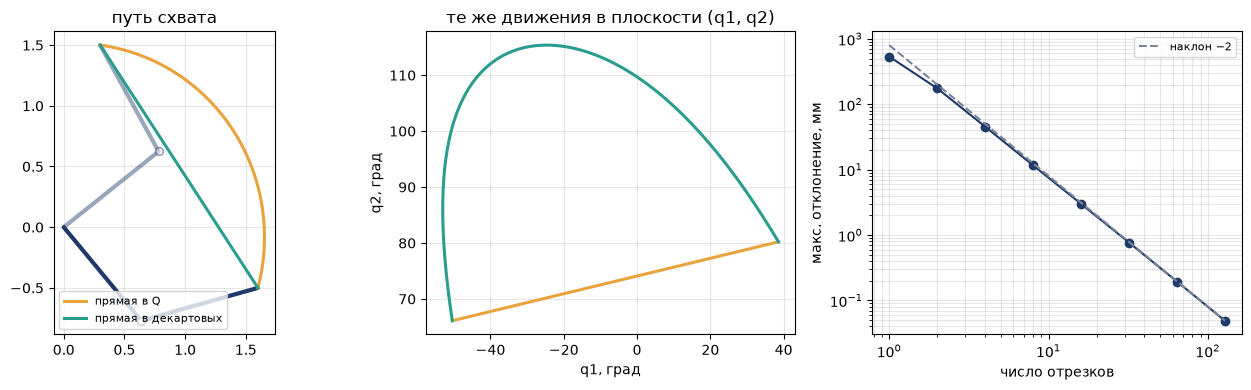

In [8]:
A = np.array([1.6, -0.5]); B = np.array([0.3, 1.5])
Qj, Pj = joint_line(A, B); Qc, Pc = cart_line(A, B)
dev = line_deviation(Pj, A, B).max()
print('уход схвата от отрезка AB при прямой в пространстве сочленений: %s м' % ru(dev))
segs = np.array([1, 2, 4, 8, 16, 32, 64, 128]); errs = np.array([split_error(A, B, n) for n in segs])
for n in (1, 8, 32, 128): print('  %3d отрезков разбиения: наибольшее отклонение %8.3f мм' % (n, errs[list(segs).index(n)] * 1000))
print('отношение ошибок при удвоении числа отрезков:', (errs[:-1] / errs[1:]).round(2))
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
ax = axs[0]; ax.set_aspect('equal'); draw_arm(ax, ik2(A)); draw_arm(ax, ik2(B), alpha=.45)
ax.plot(Pj[:, 0], Pj[:, 1], color=AMB, lw=2.2, label='прямая в Q'); ax.plot(Pc[:, 0], Pc[:, 1], color=TEAL, lw=2.2, label='прямая в декартовых'); ax.legend(fontsize=8); ax.grid(alpha=.3); ax.set_title('путь схвата')
axs[1].plot(np.degrees(Qj[:, 0]), np.degrees(Qj[:, 1]), color=AMB, lw=2.2); axs[1].plot(np.degrees(Qc[:, 0]), np.degrees(Qc[:, 1]), color=TEAL, lw=2.2)
axs[1].set_xlabel('q1, град'); axs[1].set_ylabel('q2, град'); axs[1].grid(alpha=.3); axs[1].set_title('те же движения в плоскости (q1, q2)')
axs[2].loglog(segs, errs * 1000, 'o-', color=NAVY); axs[2].loglog(segs, errs[-1] * 1000 * (segs[-1] / segs) ** 2.0, color=GREY, ls='--', label='наклон −2')
axs[2].set_xlabel('число отрезков'); axs[2].set_ylabel('макс. отклонение, мм'); axs[2].legend(fontsize=8); axs[2].grid(alpha=.3, which='both'); plt.tight_layout(); plt.show()

## 6. Окружность схвата через обратную задачу (пример 4.4 и второе домашнее задание)

**Часть а — двухзвенник.** Окружность $R=0{,}4$ м с центром $(1{,}0;\,0{,}8)$, $T=4$ с, закон $\varphi=2\pi\lambda_5(t/T)$. Берём 72 узла равномерно по времени, в каждом решаем обратную задачу итерациями Ньютона из решения для предыдущего узла (цепочка близких целей), через $\mathbf q_k$ проводим сплайны с нулевыми скоростями на концах.

итераций Ньютона на узел: от 2 до 3, в среднем 2.78; расхождение с аналитической ОЗК 1.2e-09 рад
наибольшая скорость схвата 2πR·(15/8)/T = 1,18 м/с
сплайн по 72 узлам: max|q̇1| = 1.45, max|q̇2| = 1.47 рад/с; отклонение схвата от окружности не более 0.0040 мм
для сравнения, линейная интерполяция углов между теми же узлами: 1.989 мм
ошибка хорды R(1 − cos(Δφ/2)): 36 узлов — 1,5 мм, 360 узлов — 0,015 мм


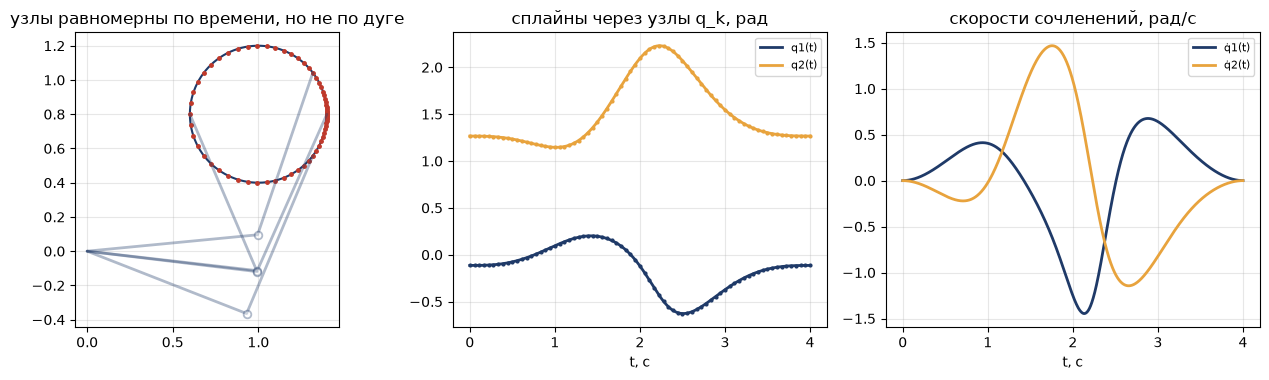

In [9]:
T, R, C0, N = 4.0, 0.4, np.array([1.0, 0.8]), 72
tn = np.linspace(0, T, N + 1); Sn = np.array([circle_ref(t, T)[0] for t in tn])
q = ik2(Sn[0]); Qn = []; iters = []
for s in Sn:
    q, it = ik2_newton(s, q, tol=1e-9); Qn.append(q.copy()); iters.append(it)
Qn = np.array(Qn)
print('итераций Ньютона на узел: от %d до %d, в среднем %.2f; расхождение с аналитической ОЗК %.1e рад' % (min(iters[1:]), max(iters), np.mean(iters[1:]), np.abs(Qn - np.array([ik2(s) for s in Sn])).max()))
print('наибольшая скорость схвата 2πR·(15/8)/T = %s м/с' % ru(2 * np.pi * R * 15 / 8 / T))
ms = [spline_m(tn, Qn[:, i], 'clamped') for i in range(2)]
tf = np.linspace(0, T, 4001); qs = [spline_eval(tn, Qn[:, i], ms[i], tf) for i in range(2)]
Pf = np.array([fk2((a_, b_)) for a_, b_ in zip(qs[0][0], qs[1][0])])
err_r = np.abs(np.linalg.norm(Pf - C0, axis=1) - R)
print('сплайн по %d узлам: max|q̇1| = %.2f, max|q̇2| = %.2f рад/с; отклонение схвата от окружности не более %.4f мм' % (N, *[spline_extrema(tn, Qn[:, i], ms[i])[0] for i in range(2)], err_r.max() * 1000))
Pl = np.array([fk2((np.interp(t_, tn, Qn[:, 0]), np.interp(t_, tn, Qn[:, 1]))) for t_ in tf])
print('для сравнения, линейная интерполяция углов между теми же узлами: %.3f мм' % (np.abs(np.linalg.norm(Pl - C0, axis=1) - R).max() * 1000))
print('ошибка хорды R(1 − cos(Δφ/2)): 36 узлов — %s мм, 360 узлов — %s мм' % (ru(chord_error(R, 36) * 1000, 1), ru(chord_error(R, 360) * 1000, 3)))
fig, axs = plt.subplots(1, 3, figsize=(13, 3.9))
ax = axs[0]; ax.set_aspect('equal'); ax.plot(Pf[:, 0], Pf[:, 1], color=NAVY, lw=1.5); ax.plot(Sn[:, 0], Sn[:, 1], '.', color=RED, ms=5)
for k in (0, 18, 36, 54): draw_arm(ax, Qn[k], alpha=.35, lw=2)
ax.set_title('узлы равномерны по времени, но не по дуге'); ax.grid(alpha=.3)
for i, col in enumerate((NAVY, AMB)):
    axs[1].plot(tf, qs[i][0], color=col, lw=2, label='q%d(t)' % (i + 1)); axs[1].plot(tn, Qn[:, i], '.', color=col, ms=4); axs[2].plot(tf, qs[i][1], color=col, lw=2, label='q̇%d(t)' % (i + 1))
for ax, ttl in zip(axs[1:], ('сплайны через узлы q_k, рад', 'скорости сочленений, рад/с')): ax.set_title(ttl); ax.set_xlabel('t, с'); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Часть б — шестизвенник из `kinlib` (как во втором домашнем задании).** Схват `make_ur()` обходит окружность радиуса $0{,}15$ м в вертикальной плоскости, ориентация схвата постоянна. Аналитического решения не используем: в каждом узле — итерационная обратная задача `inverse_numerical` с начальным приближением из предыдущего узла. Следим за числом итераций и за тем, что углы меняются непрерывно (ветвь решения не перескакивает).

узлов: 73; итераций на узел: от 1 до 3, в среднем 2.84
наибольшая невязка положения в узлах 9.36e-07 м; наибольший скачок угла между соседними узлами 1.87 град
сплайн в пространстве сочленений: отклонение схвата от окружности между узлами не более 0.001 мм


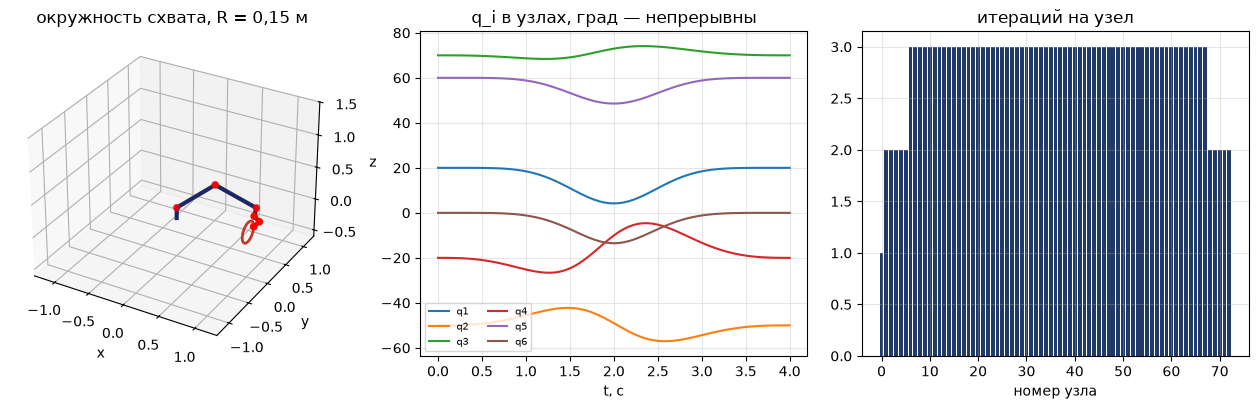

In [10]:
robot = make_ur(); robot.final_loss = 1e-6
q_init = np.radians([20., -50., 70., -20., 60., 0.])
T0 = robot.forward(q_init); R0 = T0.r_3_3.copy(); p0 = T0.t_3_1.reshape(3).copy()
Rc, Nc = 0.15, 72
centre = p0 - np.array([0.0, Rc, 0.0])
lam_n = lam_poly5(np.linspace(0, 1, Nc + 1))[0]
q = q_init.copy(); Q6 = []; it6 = []; P6 = []; Pt = []
for l in lam_n:
    ph = 2 * np.pi * l
    p = centre + Rc * np.array([0.0, np.cos(ph), np.sin(ph)])
    q = np.array(robot.inverse_numerical(Frame.from_r_3_3(R0, p.reshape(3, 1)), q0=q, step_size=1.0), dtype=float).copy()
    Q6.append(q); it6.append(len(robot.inv_history)); P6.append(robot.end_frame.t_3_1.reshape(3).copy()); Pt.append(p)
Q6 = np.unwrap(np.array(Q6), axis=0); P6 = np.array(P6); Pt = np.array(Pt)
print('узлов: %d; итераций на узел: от %d до %d, в среднем %.2f' % (Nc + 1, min(it6), max(it6), np.mean(it6)))
print('наибольшая невязка положения в узлах %.2e м; наибольший скачок угла между соседними узлами %.2f град' % (np.linalg.norm(P6 - Pt, axis=1).max(), np.degrees(np.abs(np.diff(Q6, axis=0)).max())))
# сплайны по всем шести координатам и проверка пути схвата между узлами
tn6 = np.linspace(0, 4.0, Nc + 1); tf6 = np.linspace(0, 4.0, 721)
Qf = np.array([spline_eval(tn6, Q6[:, i], spline_m(tn6, Q6[:, i], 'clamped'), tf6)[0] for i in range(6)]).T
Pf6 = np.array([robot.forward(qq).t_3_1.reshape(3).copy() for qq in Qf])
dev6 = np.sqrt((np.linalg.norm(Pf6[:, 1:] - centre[1:], axis=1) - Rc) ** 2 + (Pf6[:, 0] - centre[0]) ** 2)
print('сплайн в пространстве сочленений: отклонение схвата от окружности между узлами не более %.3f мм' % (dev6.max() * 1000))
fig = plt.figure(figsize=(13, 4.2)); ax = fig.add_subplot(1, 3, 1, projection='3d')
robot.forward(Q6[0]); robot.draw(ax=ax, cylinders=False, frame_len=0.0); ax.plot(Pf6[:, 0], Pf6[:, 1], Pf6[:, 2], color=RED, lw=2); ax.set_title('окружность схвата, R = 0,15 м')
ax2 = fig.add_subplot(1, 3, 2); ax2.plot(tn6, np.degrees(Q6)); ax2.set_title('q_i в узлах, град — непрерывны'); ax2.set_xlabel('t, с'); ax2.grid(alpha=.3); ax2.legend(['q%d' % (i + 1) for i in range(6)], fontsize=7, ncol=2)
ax3 = fig.add_subplot(1, 3, 3); ax3.bar(np.arange(Nc + 1), it6, color=NAVY); ax3.set_title('итераций на узел'); ax3.set_xlabel('номер узла'); ax3.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7. Управление по вектору скорости с обратной связью по положению (пример 4.5)

Закон $\dot{\mathbf q}=J^{+}(\mathbf q)\bigl(\dot{\mathbf s}^{\ast}+K\mathbf e\bigr)$, $\mathbf e=\mathbf s^{\ast}-\mathbf f(\mathbf q)$, интегрирование по Эйлеру с тактом $\Delta t=0{,}02$ с. Окружность примера 4.4. Ожидаем наибольшую ошибку $23$, $8{,}6$ и $2{,}6$ мм при $K=0$, $5$, $20$ с$^{-1}$; при начальном смещении $78$ мм и $K=20$ выход на окружность примерно за $0{,}2$ с.

K =  0: старт с окружности — макс. ошибка  22.8 мм, в конце  15.73 мм | старт со смещением 78 мм — через 0,2 с:  78.4 мм, в конце  77.23 мм
K =  5: старт с окружности — макс. ошибка   8.6 мм, в конце   0.65 мм | старт со смещением 78 мм — через 0,2 с:  27.4 мм, в конце   0.65 мм
K = 20: старт с окружности — макс. ошибка   2.6 мм, в конце   0.05 мм | старт со смещением 78 мм — через 0,2 с:   0.6 мм, в конце   0.05 мм


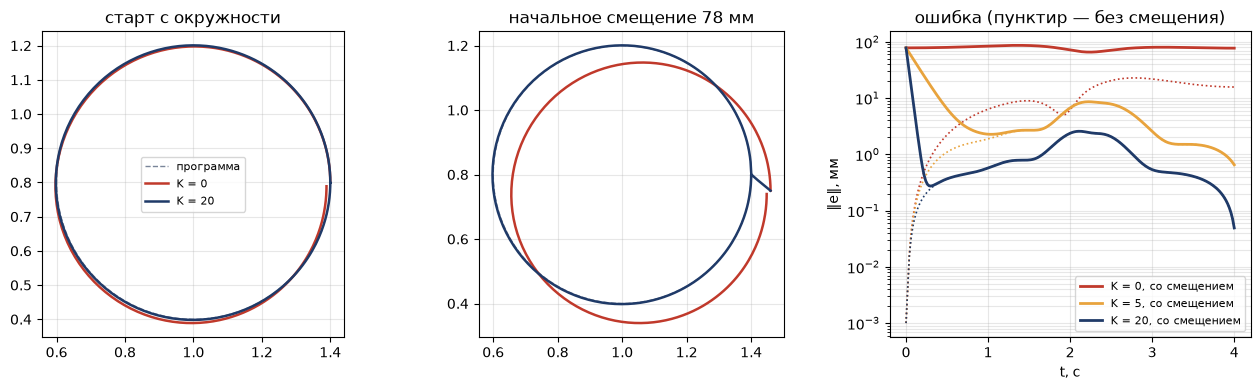

In [11]:
off = (0.06, -0.05); cols = {0: RED, 5: AMB, 20: NAVY}
res0 = {K: track(K) for K in (0, 5, 20)}; res1 = {K: track(K, off=off) for K in (0, 5, 20)}
for K in (0, 5, 20):
    print('K = %2d: старт с окружности — макс. ошибка %5.1f мм, в конце %6.2f мм | старт со смещением %.0f мм — через 0,2 с: %5.1f мм, в конце %6.2f мм'
          % (K, res0[K][2].max() * 1000, res0[K][2][-1] * 1000, res1[K][2][0] * 1000, res1[K][2][10] * 1000, res1[K][2][-1] * 1000))
ph = np.linspace(0, 2 * np.pi, 300)
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, r, ttl in ((axs[0], res0, 'старт с окружности'), (axs[1], res1, 'начальное смещение 78 мм')):
    ax.set_aspect('equal'); ax.plot(1 + .4 * np.cos(ph), .8 + .4 * np.sin(ph), color=GREY, ls='--', lw=1, label='программа')
    for K in (0, 20): ax.plot(r[K][1][:, 0], r[K][1][:, 1], color=cols[K], lw=1.8, label='K = %d' % K)
    ax.set_title(ttl); ax.grid(alpha=.3)
axs[0].legend(fontsize=8, loc='center')
for K in (0, 5, 20):
    axs[2].semilogy(res1[K][0], res1[K][2] * 1000 + 1e-3, color=cols[K], lw=2, label='K = %d, со смещением' % K); axs[2].semilogy(res0[K][0], res0[K][2] * 1000 + 1e-3, color=cols[K], lw=1.2, ls=':')
axs[2].set_xlabel('t, с'); axs[2].set_ylabel('‖e‖, мм'); axs[2].legend(fontsize=8); axs[2].grid(alpha=.3, which='both'); axs[2].set_title('ошибка (пунктир — без смещения)'); plt.tight_layout(); plt.show()

K =  20, KΔt = 0.4, множитель за такт +0.6: ошибка через 1 с 2.51 мм
K =  50, KΔt = 1.0, множитель за такт +0.0: ошибка через 1 с 0.384 мм
K =  90, KΔt = 1.8, множитель за такт -0.8: ошибка через 1 с 0.0726 мм
K = 105, KΔt = 2.1, множитель за такт -1.1: ошибка через 1 с 587 мм


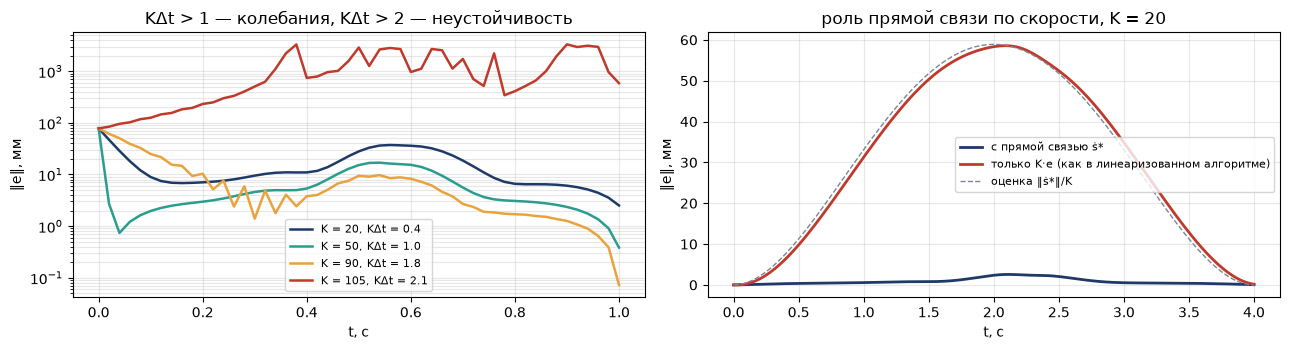

In [12]:
# Предел по коэффициенту: за такт ошибка умножается на (1 − KΔt). Без прямой связи схват отстаёт на ‖ṡ*‖/K.
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
for K, col in ((20, NAVY), (50, TEAL), (90, AMB), (105, RED)):
    ts, P, E, QD = track(K, off=off, T=1.0)
    axs[0].semilogy(ts, E * 1000 + 1e-4, color=col, lw=1.8, label='K = %d, KΔt = %.1f' % (K, K * 0.02))
    print('K = %3d, KΔt = %.1f, множитель за такт %+.1f: ошибка через 1 с %.3g мм' % (K, K * 0.02, 1 - K * 0.02, E[-1] * 1000))
axs[0].set_title('KΔt > 1 — колебания, KΔt > 2 — неустойчивость'); axs[0].set_xlabel('t, с'); axs[0].set_ylabel('‖e‖, мм'); axs[0].legend(fontsize=8); axs[0].grid(alpha=.3, which='both')
for ff, col, name in ((True, NAVY, 'с прямой связью ṡ*'), (False, RED, 'только K·e (как в линеаризованном алгоритме)')):
    ts, P, E, QD = track(20, ff=ff); axs[1].plot(ts, E * 1000, color=col, lw=2, label=name)
vref = np.array([np.linalg.norm(circle_ref(t, 4.0)[1]) for t in ts]); axs[1].plot(ts, vref / 20 * 1000, color=GREY, ls='--', lw=1, label='оценка ‖ṡ*‖/K')
axs[1].set_title('роль прямой связи по скорости, K = 20'); axs[1].set_xlabel('t, с'); axs[1].set_ylabel('‖e‖, мм'); axs[1].legend(fontsize=8); axs[1].grid(alpha=.3); plt.tight_layout(); plt.show()

## 8. Проход рядом с особой точкой и демпфирование

Схват идёт со скоростью $v=0{,}4$ м/с по прямой $y=d$ мимо основания; над основанием рука сложена, $q_2=\pi$. Ожидаем пик $\lvert\dot q_1\rvert\approx v/d$: $2$, $4$ и $8$ рад/с при $d=0{,}2$, $0{,}1$ и $0{,}05$ м. Демпфирование $\lambda=0{,}15$ при $d=0{,}05$ м: пик $2{,}4$ рад/с ценой временной ошибки $81$ мм.

d = 0,20 м: пик |q̇1| = 2,01 рад/с, оценка v/d = 2 рад/с
d = 0,10 м: пик |q̇1| = 4,01 рад/с, оценка v/d = 4 рад/с


d = 0,05 м: пик |q̇1| = 8,06 рад/с, оценка v/d = 8 рад/с
демпфирование λ = 0,15 при d = 0,05 м: пик 2,4 рад/с, наибольшая ошибка 81 мм, ошибка в конце 1.59 мм


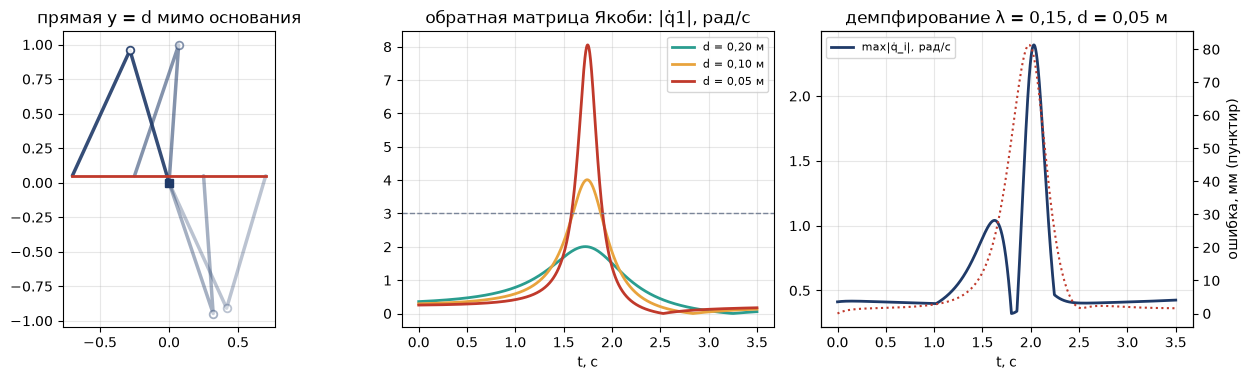

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.9))
ax = axs[0]; ax.set_aspect('equal')
for x_, al in ((-0.7, .9), (-0.25, .55), (0.25, .4), (0.7, .3)): draw_arm(ax, ik2(np.array([x_, 0.05])), alpha=al, lw=2.5)
ax.plot([-0.7, 0.7], [0.05, 0.05], color=RED, lw=2); ax.plot(0, 0, 's', color=NAVY); ax.set_title('прямая y = d мимо основания'); ax.grid(alpha=.3)
for d_, col in ((0.2, TEAL), (0.1, AMB), (0.05, RED)):
    ts, QD, E, P, S = pass_near(d_, 'inv')
    axs[1].plot(ts, np.abs(QD[:, 0]), color=col, lw=2, label='d = %s м' % ru(d_))
    print('d = %s м: пик |q̇1| = %s рад/с, оценка v/d = %s рад/с' % (ru(d_), ru(np.abs(QD[:, 0]).max()), ru(0.4 / d_, 0)))
axs[1].axhline(3.0, color=GREY, ls='--', lw=1); axs[1].set_title('обратная матрица Якоби: |q̇1|, рад/с'); axs[1].set_xlabel('t, с'); axs[1].legend(fontsize=8); axs[1].grid(alpha=.3)
ts, QD, E, P, S = pass_near(0.05, 'dls', lam=0.15)
print('демпфирование λ = 0,15 при d = 0,05 м: пик %s рад/с, наибольшая ошибка %.0f мм, ошибка в конце %.2f мм' % (ru(np.abs(QD).max(), 1), E.max() * 1000, E[-1] * 1000))
axs[2].plot(ts, np.abs(QD).max(axis=1), color=NAVY, lw=2, label='max|q̇_i|, рад/с'); axb = axs[2].twinx(); axb.plot(ts, E * 1000, color=RED, lw=1.5, ls=':'); axb.set_ylabel('ошибка, мм (пунктир)')
axs[2].set_title('демпфирование λ = 0,15, d = 0,05 м'); axs[2].set_xlabel('t, с'); axs[2].legend(fontsize=8, loc='upper left'); axs[2].grid(alpha=.3); plt.tight_layout(); plt.show()

## 9. Ограничение скоростей приводов

Предел приводов $3$ рад/с, прямая $d=0{,}05$ м. Три способа: срезание каждой компоненты по отдельности (неправильно — меняется направление скорости схвата), общее масштабирование $\dot{\mathbf q}\leftarrow\dot{\mathbf q}/k$ (направление сохраняется, схват отстаёт от программы), масштабирование времени — замедление самой программы в $k$ раз (сохраняются и путь, и отсутствие отставания, теряется только время).

срезание по компонентам  пик 3.0 рад/с | уход схвата с линии y = d:  38.42 мм | отставание от программы:   87.9 мм | время прохода 3.50 с


общее масштабирование    пик 3.0 рад/с | уход схвата с линии y = d:   0.54 мм | отставание от программы:  114.8 мм | время прохода 3.50 с


замедление программы     пик 3.0 рад/с | уход схвата с линии y = d:   0.14 мм | отставание от программы:    0.3 мм | время прохода 3.79 с


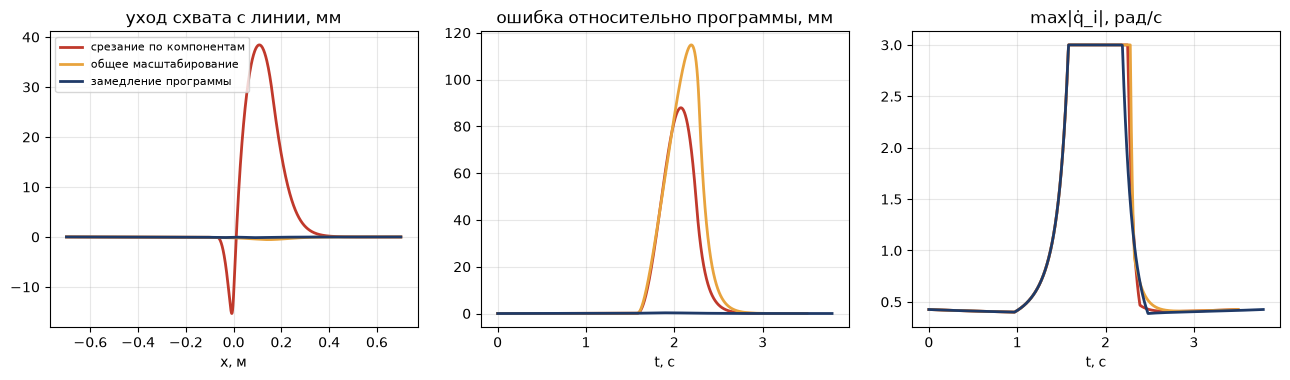

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.9))
for lim, col, name in (('clip', RED, 'срезание по компонентам'), ('scale', AMB, 'общее масштабирование'), ('time', NAVY, 'замедление программы')):
    ts, QD, E, P, S = pass_near(0.05, 'inv', qmax=3.0, limit=lim)
    print('%-24s пик %.1f рад/с | уход схвата с линии y = d: %6.2f мм | отставание от программы: %6.1f мм | время прохода %.2f с'
          % (name, np.abs(QD).max(), np.abs(P[:, 1] - 0.05).max() * 1000, E.max() * 1000, ts[-1]))
    axs[0].plot(P[:, 0], (P[:, 1] - 0.05) * 1000, color=col, lw=2, label=name); axs[1].plot(ts, E * 1000, color=col, lw=2); axs[2].plot(ts, np.abs(QD).max(axis=1), color=col, lw=2)
axs[0].set_title('уход схвата с линии, мм'); axs[0].set_xlabel('x, м'); axs[0].legend(fontsize=8)
axs[1].set_title('ошибка относительно программы, мм'); axs[1].set_xlabel('t, с'); axs[2].set_title('max|q̇_i|, рад/с'); axs[2].set_xlabel('t, с')
for ax in axs: ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 10. Интерактивная модель (запускать вживую)

Ползунки: время обхода $T$, коэффициент обратной связи $K$, параметр демпфирования $\lambda$, расстояние $d$ прямой от основания. Путь — окружность примера 4.4 или прямая мимо особой точки.

In [15]:
def show_tracking(path='окружность', T=4.0, K=20.0, lam=0.0, d=0.05):
    if path == 'окружность':
        ts, P, E, QD = track(K, T=T, off=(0.06, -0.05), lam=lam)
        ref = np.array([circle_ref(t, T)[0] for t in ts])
    else:
        ts, QD, E, P, ref = pass_near(d, 'dls' if lam > 0 else 'inv', lam=lam, K=K, v=1.4 / T)
    fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
    axs[0].set_aspect('equal'); axs[0].plot(ref[:, 0], ref[:, 1], color=GREY, ls='--'); axs[0].plot(P[:, 0], P[:, 1], color=NAVY, lw=2); axs[0].plot(0, 0, 's', color=NAVY); axs[0].set_title('путь схвата')
    axs[1].plot(ts, QD); axs[1].set_title('q̇_i(t), рад/с; пик %.2f' % np.abs(QD).max()); axs[2].plot(ts, E * 1000, color=RED); axs[2].set_title('ошибка, мм; максимум %.1f' % (E.max() * 1000))
    for ax in axs: ax.grid(alpha=.3)
    plt.tight_layout(); plt.show()
try:
    from ipywidgets import interact, FloatSlider, Dropdown
    interact(show_tracking, path=Dropdown(options=['окружность', 'прямая у особой точки'], value='окружность'),
             T=FloatSlider(min=1, max=8, step=0.5, value=4), K=FloatSlider(min=0, max=110, step=5, value=20),
             lam=FloatSlider(min=0, max=0.4, step=0.05, value=0), d=FloatSlider(min=0.02, max=0.3, step=0.01, value=0.05))
except ImportError:
    print('установите ipywidgets: pip install ipywidgets'); show_tracking()

interactive(children=(Dropdown(description='path', options=('окружность', 'прямая у особой точки'), value='окр…